# UTS Data Mining — Klasifikasi Kualitas Anggur (Wine Quality)

**Mata Kuliah:** Data Mining | **Prodi:** D3 Statistika Terapan dan Komputasi, UNNES
**Sifat:** Take Home Test | **Tujuan:** memprediksi variabel `quality` pada `data_testing.csv` menggunakan model klasifikasi yang dilatih dari `data_training.csv`.

**Alur kerja:** 1) Persiapan data → 2) Pembersihan data → 3) Pembuatan model → 4) Prediksi data uji → 5) Pengumpulan hasil.

## 0. Pengaturan
Ganti `NIM3` dengan **3 digit terakhir NIM** kamu. Jika dijalankan di Google Colab, upload `data_training.csv` dan `data_testing.csv` (dan file template `hasilprediksi` bila ada) ke panel *Files* di sebelah kiri.

In [22]:
NIM3 = "028"
TRAIN_PATH = "data_training.csv"
TEST_PATH = "data_testing.csv"
TEMPLATE_PATH = None              # isi mis. "hasilprediksi_format.csv" jika file template dari dosen ada
TARGET = "quality"
RANDOM_STATE = 42

## 1. Persiapan Data
Mengimpor library dan memuat kedua dataset.

In [23]:
import warnings, os
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

sns.set_style("whitegrid")
train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)
print("Ukuran data training:", train.shape)
print("Ukuran data testing :", test.shape)
train.head()

Ukuran data training: (857, 13)
Ukuran data testing : (286, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.3,0.740,0.08,1.7,0.094,10.0,45.0,0.99576,3.24,0.50,9.8,5,1366
1,8.1,0.575,0.22,2.1,0.077,12.0,65.0,0.99670,3.29,0.51,9.2,5,103
2,10.1,0.430,0.40,2.6,0.092,13.0,52.0,0.99834,3.22,0.64,10.0,7,942
3,12.9,0.500,0.55,2.8,0.072,7.0,24.0,1.00012,3.09,0.68,10.9,6,811
4,8.4,0.360,0.32,2.2,0.081,32.0,79.0,0.99640,3.30,0.72,11.0,6,918


In [24]:
test.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,Id
0,6.8,0.61,0.04,1.5,0.057,5.0,10.0,0.99525,3.42,0.60,9.500000,222
1,6.9,0.84,0.21,4.1,0.074,16.0,65.0,0.99842,3.53,0.72,9.233333,1514
2,7.0,0.58,0.12,1.9,0.091,34.0,124.0,0.99560,3.44,0.48,10.500000,417
3,7.8,0.48,0.68,1.7,0.415,14.0,32.0,0.99656,3.09,1.06,9.100000,754
4,12.5,0.60,0.49,4.3,0.100,5.0,14.0,1.00100,3.25,0.74,11.900000,516


In [25]:
# Identifikasi kolom ID (tidak boleh dipakai sebagai fitur)
ID_COL = next((c for c in test.columns if c.lower() == "id"), None)
print("Kolom ID pada data testing:", ID_COL)
print("Kolom training:", list(train.columns))
print("Kolom testing :", list(test.columns))
train.info()

Kolom ID pada data testing: Id
Kolom training: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality', 'Id']
Kolom testing : ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'Id']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 857 entries, 0 to 856
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         857 non-null    float64
 1   volatile acidity      857 non-null    float64
 2   citric acid           857 non-null    float64
 3   residual sugar        857 non-null    float64
 4   chlorides             857 non-null    float64
 5   free sulfur dioxide   857 non-null    float64
 6   total sulfur dioxide  857 non-null    float64
 7   d

**Interpretasi:** Data training berisi 857 baris dengan 11 fitur kimiawi, kolom target `quality`, dan kolom `Id`. Kolom `Id` hanya penanda baris sehingga dikeluarkan dari fitur agar model tidak mempelajari informasi yang tidak bermakna. Data testing memiliki struktur yang sama tetapi tanpa kolom `quality`. Seluruh kolom pada data training berjumlah 857, yang menunjukkan tidak ada nilai hilang. Rata-rata `quality` adalah 5,65 dengan rentang nilai 3 sampai 8.

### 1.1 Eksplorasi Data (EDA)

In [26]:
train.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,857.0,8.261960,1.701992,4.60000,7.10000,7.90000,9.1000,15.6000
volatile acidity,857.0,0.529393,0.179162,0.12000,0.39500,0.52000,0.6400,1.5800
citric acid,857.0,0.267351,0.195144,0.00000,0.09000,0.25000,0.4200,1.0000
residual sugar,857.0,2.506184,1.293512,0.90000,1.90000,2.20000,2.6000,15.5000
chlorides,857.0,0.086830,0.048721,0.01200,0.07000,0.07900,0.0900,0.6110
free sulfur dioxide,857.0,15.782964,10.300402,1.00000,7.00000,14.00000,21.0000,68.0000
total sulfur dioxide,857.0,45.978413,31.692113,6.00000,21.00000,38.00000,63.0000,278.0000
density,857.0,0.996692,0.001901,0.99007,0.99552,0.99668,0.9978,1.0032
pH,857.0,3.313092,0.152079,2.74000,3.21000,3.31000,3.4000,4.0100
sulphates,857.0,0.656709,0.167364,0.39000,0.55000,0.62000,0.7300,2.0000


quality
3      6
4     26
5    362
6    341
7    109
8     13
Name: count, dtype: int64


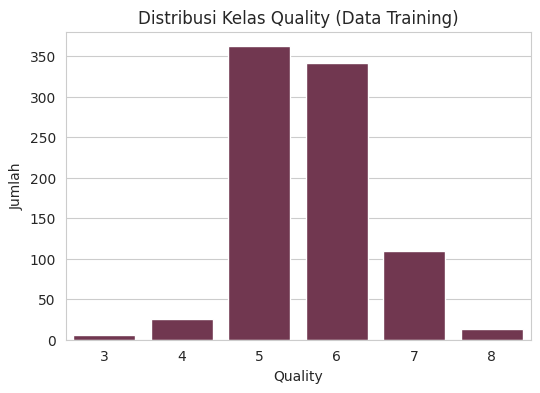

In [27]:
# Distribusi target
counts = train[TARGET].value_counts().sort_index()
print(counts)
plt.figure(figsize=(6,4))
sns.barplot(x=counts.index, y=counts.values, color="#7b2d4f")
plt.title("Distribusi Kelas Quality (Data Training)")
plt.xlabel("Quality"); plt.ylabel("Jumlah")
plt.show()

**Interpretasi:** Kelas `quality` sangat tidak seimbang. Kelas 5 (362 sampel, 42,2%) dan kelas 6 (341 sampel, 39,8%) mendominasi dengan total 82% data. Kelas 7 berjumlah 109 sampel (12,7%), sedangkan kelas 4 (26), kelas 8 (13), dan kelas 3 (6) sangat sedikit. Kondisi ini membuat model cenderung belajar mengenali kelas mayoritas, sehingga kelas minoritas sulit diprediksi dan akurasi keseluruhan perlu dibaca bersama metrik per kelas.

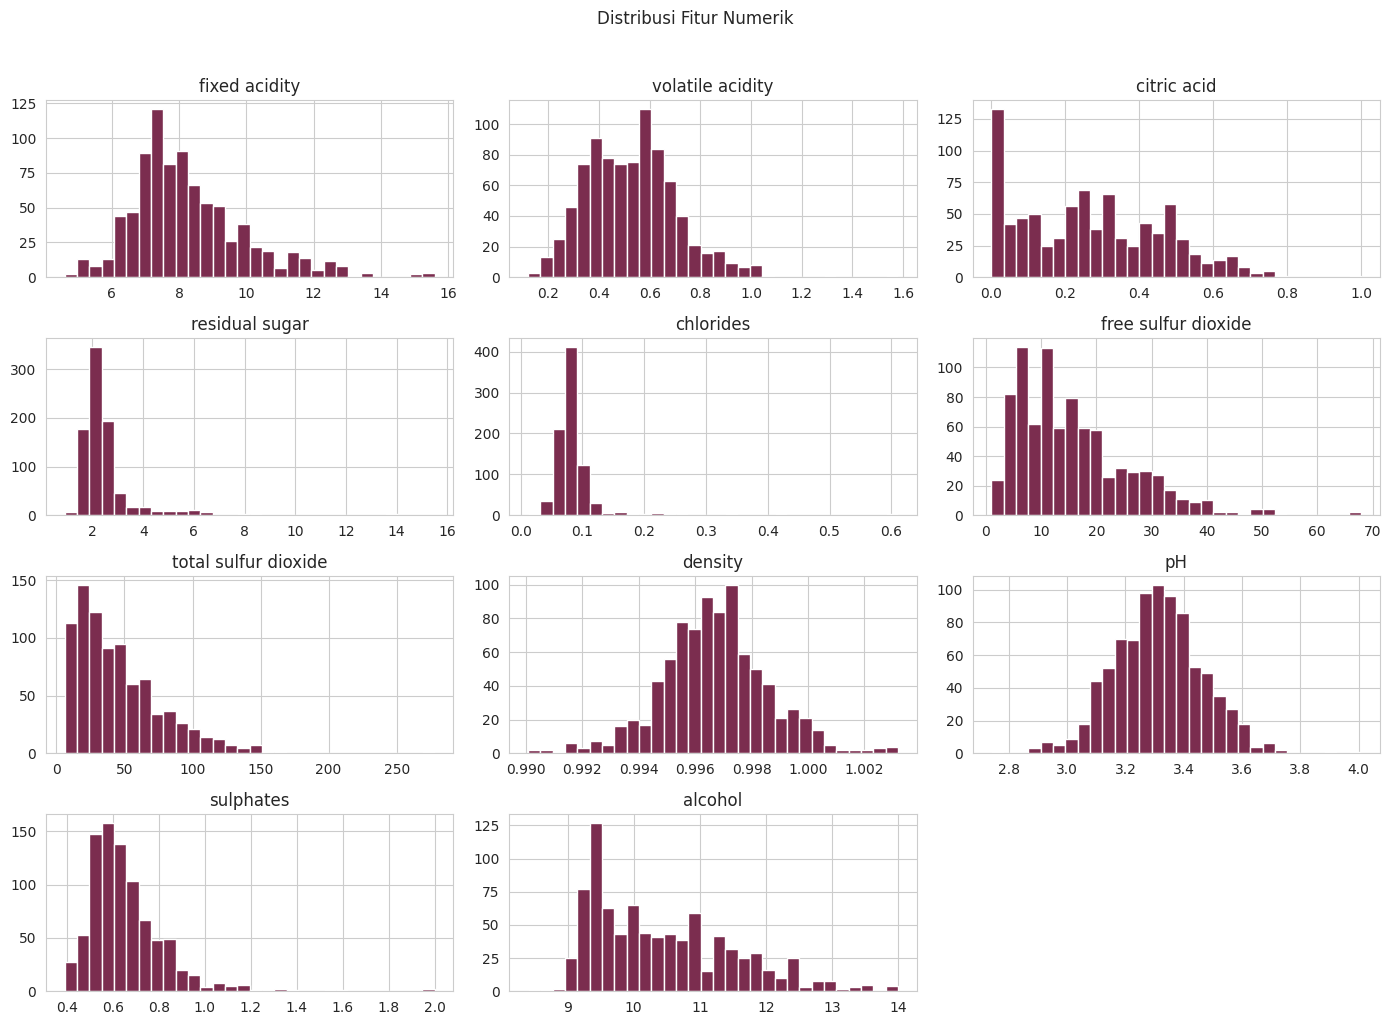

In [28]:
num_cols = train.select_dtypes(include=np.number).columns.drop([c for c in [TARGET, ID_COL] if c in train.columns])
train[num_cols].hist(bins=30, figsize=(14,10), color="#7b2d4f")
plt.suptitle("Distribusi Fitur Numerik", y=1.02)
plt.tight_layout(); plt.show()

**Interpretasi:** Sebagian besar fitur berdistribusi menjulur ke kanan (*right-skewed*), terutama `residual sugar`, `chlorides`, `free sulfur dioxide`, `total sulfur dioxide`, dan `sulphates`. Fitur `density` dan `pH` mendekati distribusi normal. `citric acid` memiliki banyak nilai 0, yang berarti banyak sampel tidak mengandung asam sitrat.

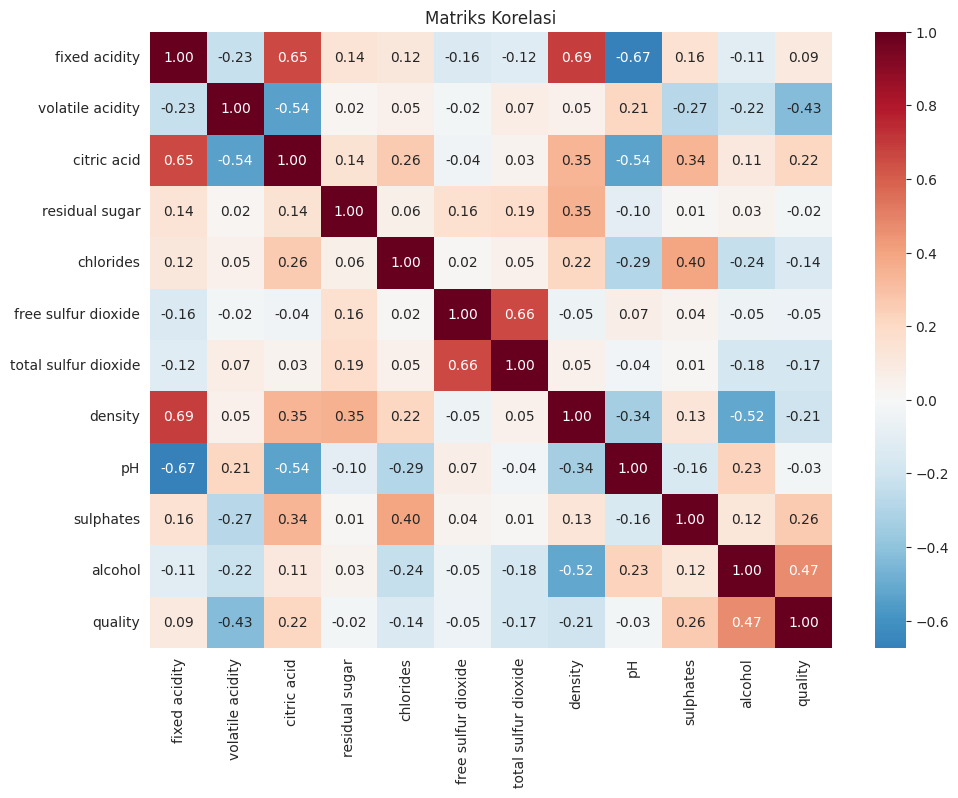

alcohol                 0.473555
sulphates               0.260703
citric acid             0.221263
fixed acidity           0.092714
residual sugar         -0.020511
pH                     -0.033199
free sulfur dioxide    -0.054509
chlorides              -0.144946
total sulfur dioxide   -0.172737
density                -0.207903
volatile acidity       -0.430059
Name: quality, dtype: float64


In [29]:
plt.figure(figsize=(11,8))
corr = train.select_dtypes(include=np.number).drop(columns=[c for c in [ID_COL] if c in train.columns]).corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Matriks Korelasi")
plt.show()
print(corr[TARGET].drop(TARGET).sort_values(ascending=False))

**Interpretasi:** Fitur yang paling berhubungan dengan `quality` adalah `alcohol` (r = 0,47, positif) dan `volatile acidity` (r = -0,43, negatif). Artinya, anggur dengan kadar alkohol lebih tinggi dan keasaman volatil lebih rendah cenderung berkualitas lebih baik. Fitur berikutnya adalah `sulphates` (0,26), `citric acid` (0,22), dan `density` (-0,21). Fitur `residual sugar` (-0,02), `pH` (-0,03), dan `free sulfur dioxide` (-0,05) hampir tidak berkorelasi linear dengan kualitas.

Terdapat korelasi antar fitur yang cukup tinggi, seperti `fixed acidity` dengan `density` (0,69), `fixed acidity` dengan `pH` (-0,67), `fixed acidity` dengan `citric acid` (0,65), serta `free` dengan `total sulfur dioxide` (0,66). Ini menandakan potensi multikolinearitas yang dapat mengganggu model linear, tetapi relatif aman bagi model berbasis pohon.

## 2. Pembersihan Data

In [30]:
print("Missing values - training:")
print(train.isnull().sum()[train.isnull().sum() > 0] if train.isnull().sum().sum() else "Tidak ada missing value")
print("\nMissing values - testing:")
print(test.isnull().sum()[test.isnull().sum() > 0] if test.isnull().sum().sum() else "Tidak ada missing value")
print("\nData duplikat (training):", train.drop(columns=[c for c in [ID_COL] if c in train.columns]).duplicated().sum())

Missing values - training:
Tidak ada missing value

Missing values - testing:
Tidak ada missing value

Data duplikat (training): 76


**Interpretasi dan penanganan:** Pada data training tidak ditemukan missing value (seluruh kolom berjumlah 857). Hasil pemeriksaan missing value pada data testing dan data duplikat ditampilkan pada output di atas. Meskipun tidak ada missing value, penanganan tetap disiapkan melalui imputasi **median** di dalam *pipeline* (tahan terhadap outlier). Statistik median hanya dihitung dari data training sehingga tidak terjadi kebocoran data, dan otomatis diterapkan juga pada data testing.

In [31]:
# Pisahkan fitur dan target
drop_cols = [c for c in [TARGET, ID_COL] if c in train.columns]
X = train.drop(columns=drop_cols)
y = train[TARGET].astype(int)

X_test_final = test.drop(columns=[c for c in [ID_COL, TARGET] if c in test.columns])

# Fitur kategorik (mis. jenis anggur red/white) -> one-hot encoding
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()
print("Fitur kategorik:", cat_cols)
X = pd.get_dummies(X, columns=cat_cols, drop_first=True)
X_test_final = pd.get_dummies(X_test_final, columns=cat_cols, drop_first=True)
X_test_final = X_test_final.reindex(columns=X.columns, fill_value=0)   # samakan kolom train & test
X = X.astype(float); X_test_final = X_test_final.astype(float)
print("Jumlah fitur akhir:", X.shape[1])

Fitur kategorik: []
Jumlah fitur akhir: 11


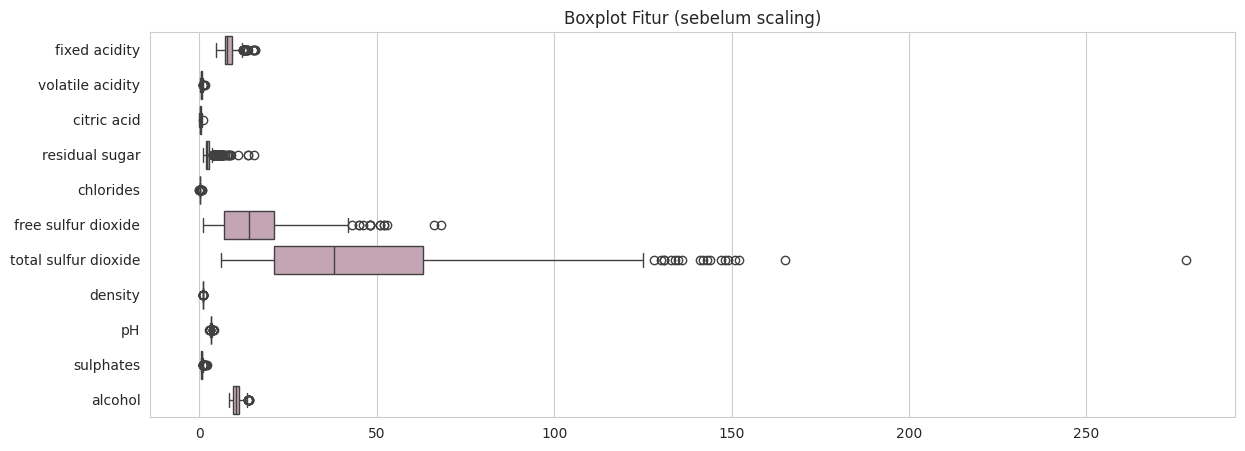

                          min       max        std
fixed acidity         4.60000   15.6000   1.701992
volatile acidity      0.12000    1.5800   0.179162
citric acid           0.00000    1.0000   0.195144
residual sugar        0.90000   15.5000   1.293512
chlorides             0.01200    0.6110   0.048721
free sulfur dioxide   1.00000   68.0000  10.300402
total sulfur dioxide  6.00000  278.0000  31.692113
density               0.99007    1.0032   0.001901
pH                    2.74000    4.0100   0.152079
sulphates             0.39000    2.0000   0.167364
alcohol               8.40000   14.0000   1.066971


In [32]:
# Pemeriksaan outlier (IQR) dan skala fitur
plt.figure(figsize=(14,5))
sns.boxplot(data=X.select_dtypes(include=np.number), orient="h", color="#c9a0b4")
plt.title("Boxplot Fitur (sebelum scaling)")
plt.show()
print(X.describe().loc[["min","max","std"]].T)

**Interpretasi:** Rentang antar fitur sangat berbeda. `total sulfur dioxide` mencapai 278, sedangkan `chlorides` dan `density` bernilai di bawah 1. Boxplot juga memperlihatkan banyak outlier, terutama pada `total sulfur dioxide`, `free sulfur dioxide`, dan `residual sugar`. Karena itu **feature scaling (`StandardScaler`)** diterapkan pada model yang sensitif terhadap skala (Logistic Regression dan KNN), sedangkan model berbasis pohon tidak membutuhkannya. Outlier **tidak dihapus** karena merupakan hasil pengukuran kimiawi yang mungkin valid, dan model berbasis pohon relatif tahan terhadap outlier.

## 3. Pembuatan Model
Data training dibagi menjadi **80% latih** dan **20% validasi** (stratified) untuk menguji model pada data yang belum pernah dilihat. Beberapa algoritma dibandingkan dengan *cross-validation* 5-fold.

In [14]:
min_class = y.value_counts().min()
strat = y if min_class >= 2 else None
X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=strat)
print("Train:", X_tr.shape, "| Validasi:", X_val.shape)

def make(model, scale=False):
    steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale: steps.append(("scaler", StandardScaler()))
    steps.append(("model", model))
    return Pipeline(steps)

models = {
    "Logistic Regression": make(LogisticRegression(max_iter=2000), scale=True),
    "KNN": make(KNeighborsClassifier(n_neighbors=7), scale=True),
    "Decision Tree": make(DecisionTreeClassifier(random_state=RANDOM_STATE)),
    "Random Forest": make(RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)),
    "Extra Trees": make(ExtraTreesClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)),
    "Gradient Boosting": make(GradientBoostingClassifier(random_state=RANDOM_STATE)),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, pipe in models.items():
    s = cross_val_score(pipe, X_tr, y_tr, cv=cv, scoring="accuracy", n_jobs=-1)
    rows.append({"Model": name, "CV Akurasi (mean)": s.mean(), "CV Std": s.std()})
    print(f"{name:22s} {s.mean():.4f} (+/- {s.std():.4f})")
cv_table = pd.DataFrame(rows).sort_values("CV Akurasi (mean)", ascending=False).reset_index(drop=True)
cv_table

Train: (685, 11) | Validasi: (172, 11)
Logistic Regression    0.5854 (+/- 0.0259)
KNN                    0.5328 (+/- 0.0386)
Decision Tree          0.5226 (+/- 0.0164)
Random Forest          0.6292 (+/- 0.0406)
Extra Trees            0.6336 (+/- 0.0301)
Gradient Boosting      0.6161 (+/- 0.0176)


,Model,CV Akurasi (mean),CV Std
0,Extra Trees,0.633577,0.030060
1,Random Forest,0.629197,0.040614
2,Gradient Boosting,0.616058,0.017639
3,Logistic Regression,0.585401,0.025869
4,KNN,0.532847,0.038624
5,Decision Tree,0.522628,0.016387


**Interpretasi:** Hasil 5-fold cross-validation menunjukkan Extra Trees memiliki akurasi tertinggi (0,6336), diikuti Random Forest (0,6292), Gradient Boosting (0,6161), Logistic Regression (0,5854), KNN (0,5328), dan Decision Tree (0,5226). Model ensemble berbasis pohon unggul dibanding model linear dan berbasis jarak karena hubungan antara fitur kimiawi dan kualitas bersifat non-linear. Decision Tree tunggal paling rendah karena cenderung overfitting, dan KNN kurang baik karena sensitif terhadap fitur yang kurang informatif.

Selisih Extra Trees dan Random Forest sangat kecil (0,004) dan masih berada dalam rentang simpangan baku, sehingga keduanya setara. Extra Trees dipilih karena akurasi rata-rata tertinggi dan simpangan baku lebih kecil (0,030 vs 0,041), artinya lebih stabil antar fold.

### 3.1 Tuning Hyperparameter

In [15]:
best_name = cv_table.loc[0, "Model"]
print("Model terbaik dari perbandingan awal:", best_name)

param_space = {
    "Random Forest": {"model__n_estimators": [200, 400, 600], "model__max_depth": [None, 15, 25],
                       "model__min_samples_split": [2, 4, 8], "model__min_samples_leaf": [1, 2, 3],
                       "model__max_features": ["sqrt", "log2", 0.5]},
    "Extra Trees":   {"model__n_estimators": [200, 400, 600], "model__max_depth": [None, 15, 25],
                       "model__min_samples_split": [2, 4, 8], "model__min_samples_leaf": [1, 2, 3],
                       "model__max_features": ["sqrt", "log2", 0.5]},
    "Gradient Boosting": {"model__n_estimators": [100, 200, 300], "model__learning_rate": [0.03, 0.05, 0.1],
                       "model__max_depth": [3, 4, 5], "model__subsample": [0.7, 0.85, 1.0]},
}
if best_name in param_space:
    search = RandomizedSearchCV(models[best_name], param_space[best_name], n_iter=15, cv=cv,
                                scoring="accuracy", random_state=RANDOM_STATE, n_jobs=-1)
    search.fit(X_tr, y_tr)
    best_model = search.best_estimator_
    print("Parameter terbaik:", search.best_params_)
    print("Akurasi CV terbaik:", round(search.best_score_, 4))
else:
    best_model = models[best_name].fit(X_tr, y_tr)
    print("Tidak ada tuning khusus untuk model ini; memakai parameter default.")

Model terbaik dari perbandingan awal: Extra Trees
Parameter terbaik: {'model__n_estimators': 600, 'model__min_samples_split': 2, 'model__min_samples_leaf': 2, 'model__max_features': 0.5, 'model__max_depth': 25}
Akurasi CV terbaik: 0.6467


**Interpretasi:** Tuning dengan `RandomizedSearchCV` (15 kombinasi, 5-fold) pada Extra Trees menghasilkan parameter terbaik `n_estimators=600`, `max_depth=25`, `max_features=0.5`, `min_samples_split=2`, dan `min_samples_leaf=2`. Akurasi CV naik dari 0,6336 menjadi 0,6467, sehingga tuning memberi peningkatan sekitar 1,3 poin persentase.

### 3.2 Evaluasi pada Data Validasi

Akurasi training  : 1.0000
Akurasi validasi  : 0.6163

Classification report (validasi):
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.00      0.00      0.00         5
           5       0.66      0.78      0.72        73
           6       0.57      0.59      0.58        68
           7       0.53      0.36      0.43        22
           8       1.00      0.33      0.50         3

    accuracy                           0.62       172
   macro avg       0.46      0.34      0.37       172
weighted avg       0.59      0.62      0.60       172



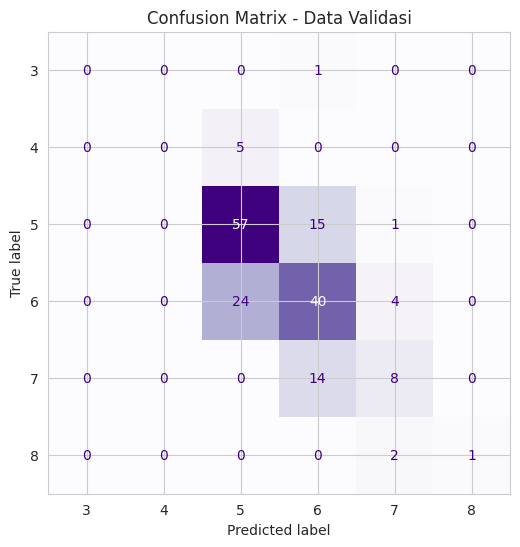

In [16]:
best_model.fit(X_tr, y_tr)
pred_tr = best_model.predict(X_tr)
pred_val = best_model.predict(X_val)
print(f"Akurasi training  : {accuracy_score(y_tr, pred_tr):.4f}")
print(f"Akurasi validasi  : {accuracy_score(y_val, pred_val):.4f}")
print("\nClassification report (validasi):")
print(classification_report(y_val, pred_val, zero_division=0))

fig, ax = plt.subplots(figsize=(7,6))
ConfusionMatrixDisplay.from_predictions(y_val, pred_val, ax=ax, cmap="Purples", colorbar=False)
ax.set_title("Confusion Matrix - Data Validasi")
plt.show()

In [17]:
from IPython.display import Markdown, display
acc_tr = accuracy_score(y_tr, pred_tr)
acc_val = accuracy_score(y_val, pred_val)
gap = acc_tr - acc_val
fmt = lambda v: f"{v:.2f}".replace(".", ",")
if gap > 0.15:
    verdict = "selisih yang besar menunjukkan model **overfitting**: model sangat baik menghafal data latih tetapi kemampuan generalisasinya pada data baru lebih rendah."
elif gap > 0.05:
    verdict = "selisih yang sedang menunjukkan **overfitting ringan**: model lebih baik pada data latih daripada data baru, yang wajar untuk model ensemble dengan banyak pohon."
else:
    verdict = "selisih yang kecil menunjukkan model **menggeneralisasi dengan baik**."
display(Markdown(f"**Interpretasi akurasi:** akurasi training {fmt(acc_tr)} dan akurasi validasi {fmt(acc_val)} (selisih {fmt(gap)}); {verdict} Akurasi validasi inilah yang lebih mencerminkan performa pada data uji."))

**Interpretasi akurasi:** akurasi training 1,00 dan akurasi validasi 0,62 (selisih 0,38); selisih yang besar menunjukkan model **overfitting**: model sangat baik menghafal data latih tetapi kemampuan generalisasinya pada data baru lebih rendah. Akurasi validasi inilah yang lebih mencerminkan performa pada data uji.


**Interpretasi:** Performa terbaik ada pada kelas mayoritas: kelas 5 (precision 0,66, recall 0,78, F1 0,72) dan kelas 6 (F1 0,58). Kelas 7 memiliki F1 0,43 dengan recall rendah (0,36), artinya banyak anggur kualitas 7 yang tidak terdeteksi. Kelas 3 dan 4 memiliki F1 0 karena tidak ada yang berhasil diprediksi, dan kelas 8 hanya memiliki 3 sampel validasi (precision 1,00, recall 0,33) sehingga angkanya tidak stabil. Rata-rata F1 makro (0,37) jauh lebih rendah daripada rata-rata tertimbang (0,60), yang menegaskan masalah ketidakseimbangan kelas.

Confusion matrix menunjukkan prediksi benar pada diagonal utama: 57 sampel kelas 5, 40 sampel kelas 6, 8 sampel kelas 7, dan 1 sampel kelas 8, atau 106 dari 172 sampel validasi. Kesalahan terutama terjadi pada kelas bertetangga, yang wajar karena skor kualitas bersifat ordinal dan batas antar kelasnya tipis:

- **Kelas 5** (73 sampel): 57 benar, 15 diprediksi sebagai 6, dan 1 sebagai 7.
- **Kelas 6** (68 sampel): 40 benar, 24 diprediksi sebagai 5, dan 4 sebagai 7.
- **Kelas 7** (22 sampel): 8 benar, sedangkan 14 diprediksi sebagai 6. Model cenderung menurunkan kualitas 7 ke kelas mayoritas.
- **Kelas 8** (3 sampel): 1 benar dan 2 diprediksi sebagai 7. Jumlah sampelnya terlalu sedikit untuk disimpulkan.
- **Kelas 3 dan 4** (1 dan 5 sampel): tidak ada yang benar. Sampel kelas 3 diprediksi sebagai 6, dan kelima sampel kelas 4 diprediksi sebagai 5.

Model cenderung memprediksi kelas yang banyak di data latih (5 dan 6) dan hampir tidak pernah memilih kelas langka. Tidak ada kesalahan yang melompat jauh, sehingga model tetap menangkap urutan kualitas dengan cukup baik.


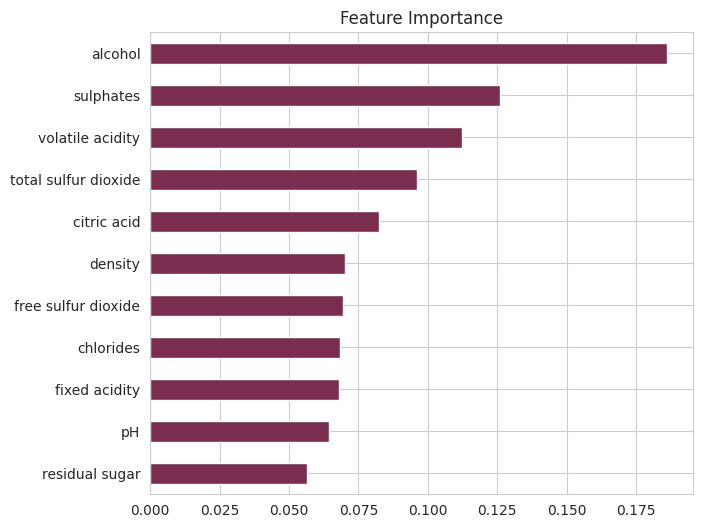

alcohol                 0.186055
sulphates               0.125861
volatile acidity        0.112433
total sulfur dioxide    0.096235
citric acid             0.082549
dtype: float64


In [18]:
# Fitur yang paling berpengaruh (jika model punya feature_importances_)
final_est = best_model.named_steps["model"]
if hasattr(final_est, "feature_importances_"):
    imp = pd.Series(final_est.feature_importances_, index=X.columns).sort_values()
    imp.plot(kind="barh", figsize=(7,6), color="#7b2d4f")
    plt.title("Feature Importance"); plt.show()
    print(imp.sort_values(ascending=False).head(5))

**Interpretasi:** Lima fitur terpenting adalah `alcohol` (0,186), `sulphates` (0,126), `volatile acidity` (0,112), `total sulfur dioxide` (0,096), dan `citric acid` (0,083). Hal ini sejalan dengan analisis korelasi, di mana `alcohol` dan `volatile acidity` paling berhubungan dengan kualitas. `Sulphates` dan `total sulfur dioxide` juga berperan besar, kemungkinan karena keduanya berkaitan dengan pengawetan dan stabilitas anggur. `Residual sugar` dan `pH` memiliki kontribusi paling kecil, konsisten dengan korelasinya yang mendekati nol.

## 4. Prediksi Data Uji
Model terbaik dilatih ulang menggunakan **seluruh** data training (agar memanfaatkan data sebanyak mungkin), disimpan, lalu dipakai memprediksi `data_testing.csv`.

In [19]:
final_model = best_model
final_model.fit(X, y)
print("Akurasi pada seluruh data training:", round(accuracy_score(y, final_model.predict(X)), 4))

# Simpan model
joblib.dump({"model": final_model, "features": list(X.columns)}, "model_wine_quality.joblib")
print("Model tersimpan: model_wine_quality.joblib")

# Deployment: muat ulang model lalu prediksi data testing
loaded = joblib.load("model_wine_quality.joblib")
pred_test = loaded["model"].predict(X_test_final[loaded["features"]])
pd.Series(pred_test).value_counts().sort_index()

Akurasi pada seluruh data training: 1.0
Model tersimpan: model_wine_quality.joblib


,count
5,130
6,131
7,25


In [20]:
# Susun file hasil prediksi: HANYA 2 kolom (ID dan quality)
id_name, q_name = (ID_COL or "Id"), "Quality"
if TEMPLATE_PATH and os.path.exists(TEMPLATE_PATH):
    tpl = pd.read_csv(TEMPLATE_PATH)
    id_name, q_name = tpl.columns[0], tpl.columns[1]      # ikuti nama kolom template dosen
ids = test[ID_COL] if ID_COL else pd.Series(np.arange(1, len(test)+1))
submission = pd.DataFrame({id_name: ids.values, q_name: pred_test.astype(int)})

out_name = f"hasilprediksi_{NIM3}.csv"
submission.to_csv(out_name, index=False)
print("File tersimpan:", out_name, "| Ukuran:", submission.shape)
submission.head(10)

File tersimpan: hasilprediksi_028.csv | Ukuran: (286, 2)


,Id,Quality
0,222,5
1,1514,6
2,417,5
3,754,5
4,516,6
5,1120,6
6,180,5
7,82,5
8,632,5
9,592,5


In [21]:
# Validasi akhir sebelum dikumpulkan
assert submission.shape[1] == 2, "File harus berisi HANYA 2 kolom"
assert len(submission) == len(test), "Jumlah baris harus sama dengan data testing"
assert submission.isnull().sum().sum() == 0, "Tidak boleh ada nilai kosong"
print("Semua pemeriksaan lolos. Siap dikumpulkan.")

Semua pemeriksaan lolos. Siap dikumpulkan.


## 5. Kesimpulan
1. Data diperiksa meliputi missing value, duplikat, distribusi target, korelasi, dan skala fitur. Target `quality` sangat tidak seimbang (kelas 5 dan 6 mencakup 82% data).
2. Enam model klasifikasi dibandingkan dengan 5-fold cross-validation. Extra Trees terbaik (akurasi CV 0,6336) dan meningkat menjadi 0,6467 setelah tuning dengan `RandomizedSearchCV`.
3. Pada data validasi, model mencapai akurasi 0,62. Model baik mengenali kualitas 5 dan 6, tetapi lemah pada kelas minoritas (3, 4, 7, 8).
4. Fitur terpenting adalah `alcohol`, `sulphates`, `volatile acidity`, `total sulfur dioxide`, dan `citric acid`.
5. Model dilatih ulang pada seluruh data training, disimpan (`model_wine_quality.joblib`), dan dipakai memprediksi data uji. Hasilnya disimpan pada `hasilprediksi_<3 digit NIM>.csv` berisi dua kolom (Id dan Quality). Prediksi data uji hanya berisi kelas 5, 6, dan 7.

**Keterbatasan:** ketidakseimbangan kelas membuat kelas langka sulit diprediksi. Perbaikan yang dapat dicoba: *class weighting*, oversampling (SMOTE), menggabungkan kelas ekstrem, atau menambah rekayasa fitur.